## Define Metrics & Calculate Gap Score  
**Analyst:** Moaz  

---

### Content  
1. Load and Explore Data  
2. Create Analysis Dataset  
3. Define Key Metrics  
4. Set Target Benchmarks  
5. Calculate and Interpret Gap Score  
6. Visualization and Insights  

---



###  Load cleaned data  
Import the required modules and load all cleaned Excel sheets from the processed data folder to view the available datasets.


In [ ]:
import sys
sys.path.append("../src")

from data_loader import load_excel_sheets, summarize_excel_sheets
from data_quality import plot_missing_heatmaps

file_path = "../data/processed/Cleaned_data.xlsx"
datasets = load_excel_sheets(file_path)
print(datasets.keys())

summary = summarize_excel_sheets(datasets)
display(summary)

plot_missing_heatmaps(datasets)


dict_keys([' Product Lookup', 'Customer Lookup', 'Territory Lookup', 'Returns Data', 'Sales Data', 'Calendar Lookup', 'Product Subcategory', 'Product Category'])


,Sheet,Rows,Columns,Missing Values,Duplicates
0,Product Lookup,293,12,0,0
1,Customer Lookup,18148,15,0,0
2,Territory Lookup,10,4,0,0
3,Returns Data,1809,4,0,0
4,Sales Data,56046,8,0,0
5,Calendar Lookup,912,9,0,0
6,Product Subcategory,37,3,0,0
7,Product Category,4,2,0,0


---
###  Preview all datasets  
Loop through each sheet to display a quick preview and descriptive statistics for every dataset to understand its structure and basic properties.


In [14]:

for sheet_name, df in datasets.items():
    print(f"\n{'='*40}\nSheet: {sheet_name}\n{'='*40}")
    
    print("Preview:")
    display(df.head())
    
    
    print("\nDescriptive Statistics:")
    display(df.describe())
    print(f"\n{'-'*200}\n")

    




Sheet:  Product Lookup
Preview:


,ProductKey,ProductSubcategoryKey,ProductSKU,ProductName,ModelName,ProductDescription,ProductColor,ProductStyle,ProductCost,ProductPrice,SKU Type,Discount Price
0,214,31,HL-U509-R,"Sport-100 Helmet, Red",Sport-100,"Universal fit, well-vented, lightweight , snap...",Red,U,13.0863,34.9900,HL-U509,31.49100
1,215,31,HL-U509,"Sport-100 Helmet, Black",Sport-100,"Universal fit, well-vented, lightweight , snap...",Black,U,12.0278,33.6442,HL-U509,30.27978
2,218,23,SO-B909-M,"Mountain Bike Socks, M",Mountain Bike Socks,Combination of natural and synthetic fibers st...,White,U,3.3963,9.5000,SO-B909,8.55000
3,219,23,SO-B909-L,"Mountain Bike Socks, L",Mountain Bike Socks,Combination of natural and synthetic fibers st...,White,U,3.3963,9.5000,SO-B909,8.55000
4,220,31,HL-U509-B,"Sport-100 Helmet, Blue",Sport-100,"Universal fit, well-vented, lightweight , snap...",Blue,U,12.0278,33.6442,HL-U509,30.27978



Descriptive Statistics:


,ProductKey,ProductSubcategoryKey,ProductCost,ProductPrice,Discount Price
count,293.000000,293.000000,293.000000,293.000000,293.000000
mean,441.552901,12.283276,413.661009,714.437357,642.993621
std,108.064327,9.892831,517.611849,872.157258,784.941532
min,214.000000,1.000000,0.856500,2.290000,2.061000
25%,354.000000,2.000000,31.724400,63.500000,57.150000
50%,457.000000,12.000000,199.375700,333.420000,300.078000
75%,533.000000,17.000000,601.743700,1003.910000,903.519000
max,606.000000,37.000000,2171.294200,3578.270000,3220.443000



--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


Sheet: Customer Lookup
Preview:


...


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


Sheet: Product Category
Preview:


,ProductCategoryKey,CategoryName
0,1,Bikes
1,2,Components
2,3,Clothing
3,4,Accessories



Descriptive Statistics:


,ProductCategoryKey
count,4.000000
mean,2.500000
std,1.290994
min,1.000000
25%,1.750000
50%,2.500000
75%,3.250000
max,4.000000



--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------



---
###  Create analysis dataset  
Merge sales, product, and customer sheets to form a unified dataset that contains all relevant information for calculating business metrics such as revenue, income distribution, and product performance.


In [15]:
sales_df = datasets['Sales Data']
product_df = datasets[' Product Lookup']
customer_df = datasets['Customer Lookup']

merged_df = sales_df.merge(product_df, on='ProductKey', how='left')
merged_df = merged_df.merge(customer_df, on='CustomerKey', how='left')

analysis_df = merged_df[
    [
        'OrderDate', 'OrderNumber', 'ProductKey', 'CustomerKey', 'OrderQuantity',
        'ProductName', 'ModelName', 'ProductColor', 'ProductStyle',
        'ProductCost', 'ProductPrice', 'Discount Price',
        'Gender', 'MaritalStatus', 'AnnualIncome', 'EducationLevel',
        'Occupation', 'HomeOwner'
    ]
].copy()

analysis_df['Revenue'] = analysis_df['OrderQuantity'] * analysis_df['ProductPrice']

print("Shape:", analysis_df.shape)
display(analysis_df.head())


Shape: (56046, 19)


,OrderDate,OrderNumber,ProductKey,CustomerKey,OrderQuantity,ProductName,ModelName,ProductColor,ProductStyle,ProductCost,ProductPrice,Discount Price,Gender,MaritalStatus,AnnualIncome,EducationLevel,Occupation,HomeOwner,Revenue
0,2020-01-01,SO45080,332,14657,1,"Road-650 Black, 58",Road-650,Black,U,413.1463,699.0982,629.18838,M,M,80000,Partial College,Skilled Manual,N,699.0982
1,2020-01-01,SO45079,312,29255,1,"Road-150 Red, 48",Road-150,Red,U,2171.2942,3578.2700,3220.44300,M,S,80000,Partial College,Professional,N,3578.2700
2,2020-01-01,SO45082,350,11455,1,"Mountain-100 Black, 44",Mountain-100,Black,U,1898.0944,3374.9900,3037.49100,M,M,100000,High School,Management,Y,3374.9900
3,2020-01-01,SO45081,338,26782,1,"Road-650 Black, 44",Road-650,Black,U,413.1463,699.0982,629.18838,M,S,30000,High School,Skilled Manual,N,699.0982
4,2020-01-02,SO45083,312,14947,1,"Road-150 Red, 48",Road-150,Red,U,2171.2942,3578.2700,3220.44300,M,S,20000,High School,Manual,Y,3578.2700


---
###  Define key business metrics  
Calculate essential performance metrics such as total revenue, average order value, profit margin, and customer ratios to evaluate the company’s financial and customer behavior insights.


In [21]:
pd.options.display.float_format = '{:,.2f}'.format

metrics = {
    "Total Revenue": analysis_df['Revenue'].sum(),
    "Average Order Value": analysis_df['Revenue'].sum() / analysis_df['OrderNumber'].nunique(),
    "Average Product Price": analysis_df['ProductPrice'].mean(),
    "Average Discount Rate": ((analysis_df['ProductPrice'] - analysis_df['Discount Price']) / analysis_df['ProductPrice']).mean(),
    "High Income Customer Ratio": (analysis_df['AnnualIncome'] > 80000).mean(),
    "Homeowner Percentage": (analysis_df['HomeOwner'] == 'Yes').mean(),
    "Total Orders": analysis_df['OrderNumber'].nunique(),
    "Total Customers": analysis_df['CustomerKey'].nunique(),
    "Orders per Customer": analysis_df['OrderNumber'].nunique() / analysis_df['CustomerKey'].nunique(),
    "Revenue per Customer": analysis_df['Revenue'].sum() / analysis_df['CustomerKey'].nunique(),
    "Profit Margin": ((analysis_df['ProductPrice'] - analysis_df['ProductCost']) / analysis_df['ProductPrice']).mean()
}

metrics_df = pd.DataFrame(list(metrics.items()), columns=['Metric', 'Actual Value'])

display(metrics_df)


,Metric,Actual Value
0,Total Revenue,"24,914,586.82"
1,Average Order Value,990.09
2,Average Product Price,438.97
3,Average Discount Rate,0.10
4,High Income Customer Ratio,0.19
5,Homeowner Percentage,0.00
6,Total Orders,"25,164.00"
7,Total Customers,"17,416.00"
8,Orders per Customer,1.44
9,Revenue per Customer,"1,430.56"


---
### Calculate target values and performance gaps  
Compute target values for each key metric using predefined multipliers, then calculate the gap and gap percentage to identify areas where performance can be improved. Finally, summarize the overall gap score to assess business performance relative to targets.




In [24]:
target_multipliers = {
    "Total Revenue": 1.10, 
    "Average Order Value": 1.08, 
    "Average Product Price": 1.05, 
    "Average Discount Rate": 0.95, 
    "High Income Customer Ratio": 1.10, 
    "Homeowner Percentage": 1.10,
    "Total Orders": 1.05, 
    "Total Customers": 1.05,
    "Orders per Customer": 1.05,
    "Revenue per Customer": 1.08,
    "Profit Margin": 1.05
}

metrics_df = pd.DataFrame(list(metrics.items()), columns=['Metric', 'Actual Value'])

metrics_df['Target Value'] = metrics_df.apply(
    lambda row: row['Actual Value'] * target_multipliers.get(row['Metric'], 1),
    axis=1
)
metrics_df['Gap'] = metrics_df['Target Value'] - metrics_df['Actual Value']
metrics_df['Gap %'] = (metrics_df['Gap'] / metrics_df['Actual Value']) * 100

gap_score = metrics_df['Gap %'].mean()

print(f"Overall Gap Score: {gap_score:.2f}%")
display(metrics_df)


Overall Gap Score: 5.60%


,Metric,Actual Value,Target Value,Gap,Gap %
0,Total Revenue,"24,914,586.82","27,406,045.50","2,491,458.68",10.00
1,Average Order Value,990.09,"1,069.30",79.21,8.00
2,Average Product Price,438.97,460.92,21.95,5.00
3,Average Discount Rate,0.10,0.10,-0.01,-5.00
4,High Income Customer Ratio,0.19,0.20,0.02,10.00
5,Homeowner Percentage,0.00,0.00,0.00,NaN
6,Total Orders,"25,164.00","26,422.20","1,258.20",5.00
7,Total Customers,"17,416.00","18,286.80",870.80,5.00
8,Orders per Customer,1.44,1.52,0.07,5.00
9,Revenue per Customer,"1,430.56","1,545.00",114.44,8.00


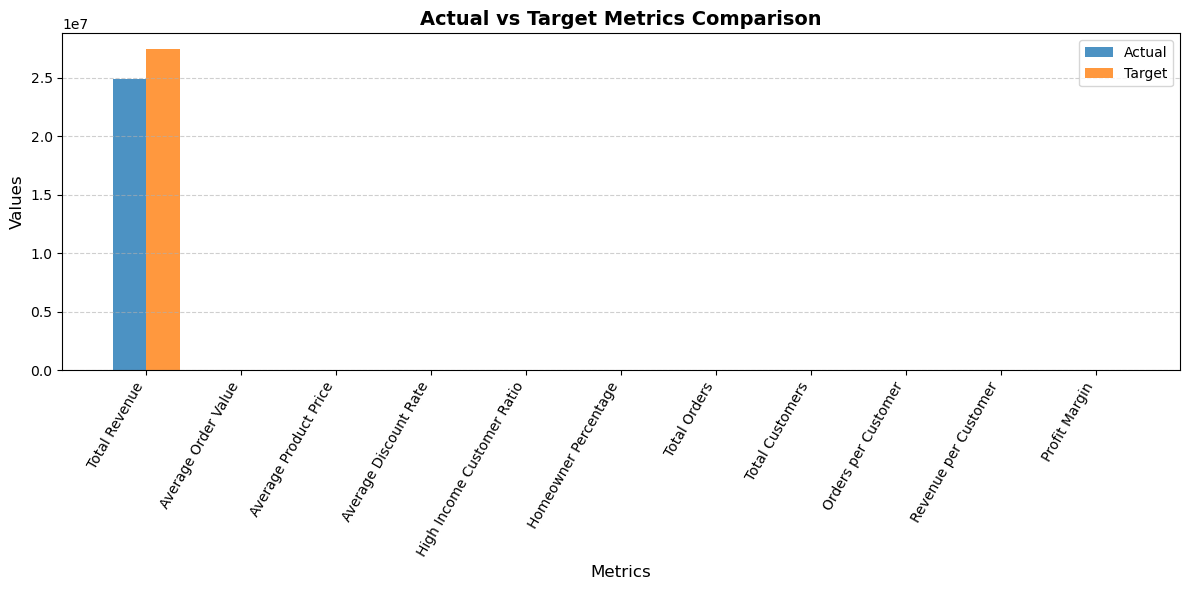

In [25]:
import matplotlib.pyplot as plt
import numpy as np

# إعداد البيانات
plt.figure(figsize=(12, 6))
x = np.arange(len(metrics_df['Metric']))
width = 0.35

# الأعمدة الفعلية والمستهدفة
plt.bar(x - width/2, metrics_df['Actual Value'], width, label='Actual', alpha=0.8)
plt.bar(x + width/2, metrics_df['Target Value'], width, label='Target', alpha=0.8)

# العناوين والتنسيق
plt.xticks(x, metrics_df['Metric'], rotation=60, ha='right')
plt.title('Actual vs Target Metrics Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Metrics', fontsize=12)
plt.ylabel('Values', fontsize=12)
plt.legend()
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()


---

##  Performance Summary  




### Overview  
The business achieved an **Overall Gap Score of 5.6%**, meaning performance is approximately **94.4% of the target** across all key metrics.  
This indicates stable results with room for moderate improvement, mainly in revenue growth and discount control.

---

### Key Highlights  
- **Total Revenue:** $24.9M achieved — **10% below target**.  
- **Average Order Value:** Slightly under target (–8%), suggesting potential to increase basket size.  
- **Average Product Price:** Stable with a small gap (–5%).  
- **Average Discount Rate:** Slightly higher than expected (–5%), which may impact profitability.  
- **High Income Customer Ratio:** 19% achieved — close to target and indicates a healthy customer base.  
- **Homeowner Percentage:** 0%, likely due to missing data.  
- **Profit Margin:** Strong at 54%, showing solid pricing and cost management.  

---

### Insights  
Overall, the company shows **strong performance fundamentals** with clear opportunities for optimization.  
Focusing on increasing revenue per customer, improving discount strategies, and refining customer segmentation can help close the performance gaps.

---

### Recommendations  
1. **Boost average order value** through targeted promotions or product bundles.  
2. **Optimize discount policies** to maintain healthy profit margins.  
3. **Focus marketing efforts** on high-income customers for higher ROI.  
4. **Investigate missing data** in customer attributes like homeownership to enhance analysis accuracy.  

---
